# Reproducibility and Statistical Re-analysis — ATRS Requirements Study

**Project 19 · Team On Top · Yashika Kamboj and Shaina Mehra**  
**Target journal:** *Requirements Engineering* (Springer Nature)

> **Important reproducibility status:** The uploaded notebook contains rendered outputs and references to external project files, but the accompanying `data/`, `demo_data/`, `scripts/`, `config.py`, and prompt files were not included. Therefore the original experiment cannot honestly be rerun from the notebook alone. This corrected notebook removes reliance on stale saved outputs, checks all inputs, and performs analysis only on supplied raw data. It does not fabricate missing observations or regenerate LLM outputs.

## What was found in the original notebook

1. It reads `data/records.csv` and `data/requirements.csv`, but runs the analysis script against `demo_data/`. Those are different input locations and may represent different datasets.
2. The displayed requirement count conflicts: one cell reports **789** (400 baseline + 389 grounded), while the saved analysis summary reports **820** total and **412 grounded**. These cannot all describe the same analysis dataset.
3. The grounded quote check in the inspection cell reports all 389 rows as `exact`, while the summary reports 78.6% exact, 17.2% near, and 4.1% no match across 412 rows. The underlying row-level data and code are needed to reconcile this.
4. The original notebook calls `06_analyze.py`, but that script and its inputs are absent. Its statistical tests, grouping, missing-data handling, and figures therefore cannot be independently verified.
5. Saved inter-rater reliability values and p-values are outputs, not reproducible evidence without the rating-level file and annotation protocol. They must not be reported as verified until recalculated.
6. A quote string matching source text is not, by itself, proof that the quote semantically supports the requirement. Human evidence-support review is still needed.

## Files required for a full rerun

Upload the original project bundle (or these files individually):
- `records.csv`: one row per ATRS record, including a unique `record_id`, `group` (high/low), `completeness`, and preferably full `source_text`.
- `requirements.csv`: one row per generated requirement, including `record_id`, `condition` (`baseline`/`grounded`), `req_id`, `requirement`, and `evidence_quote` for grounded outputs.
- `ratings.csv`: one row per rater × requirement with `req_id`, `rater_id`, `clarity`, `verifiability`, `traceability`, and `unsupported`. Traceability/unsupported coding must be defined in the codebook.
- Original prompts, model/version, generation parameters, annotation codebook, and the exact analysis script are required to reproduce generation and validate the protocol.

If the source corpus or generation outputs are missing, this notebook can re-analyse ratings but cannot regenerate the experiment. The LLM generation stage requires the actual source records and a deliberately configured model/API; it is not silently run here.

## 1. Environment and input locations

In [1]:
from pathlib import Path
import sys, json, warnings, re, math
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
ROOT = Path(".")
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__)
print("Expected input directory:", DATA_DIR.resolve())
print("Output directory:", OUT_DIR.resolve())

Python: 3.14.0
pandas: 2.3.3 | numpy: 2.4.2
Expected input directory: C:\Users\Yashika\Downloads\SEM 2\AI\atrs_project\data
Output directory: C:\Users\Yashika\Downloads\SEM 2\AI\atrs_project\outputs


## 2. Upload / locate raw files
Place the required CSVs in `data/` beside this notebook, or use the upload cell below in Colab. Do not use the old `demo_data` directory unless it is confirmed to contain the same frozen dataset.

In [2]:
# Detect local datasets or provide Colab upload fallback
local_csvs = list(DATA_DIR.glob("*.csv")) if DATA_DIR.exists() else []

if local_csvs:
    print(f"Located {len(local_csvs)} dataset files in {DATA_DIR.resolve()}: {[f.name for f in sorted(local_csvs)]}")
else:
    try:
        from google.colab import files
        print("Running in Google Colab. Please upload dataset CSV files:")
        uploaded = files.upload()
        DATA_DIR.mkdir(exist_ok=True)
        for name, content in uploaded.items():
            (DATA_DIR / name).write_bytes(content)
        print("Uploaded:", list(uploaded))
    except ImportError:
        print(f"CSV files not found in {DATA_DIR.resolve()}. Please place required CSV files in ./data/.")


Located 11 dataset files in C:\Users\Yashika\Downloads\SEM 2\AI\atrs_project\data: ['annotation_key.csv', 'annotations_A.csv', 'annotations_B.csv', 'annotations_template_A.csv', 'annotations_template_B.csv', 'atrs_records.csv', 'candidates.csv', 'ratings.csv', 'records.csv', 'requirements.csv', 'usage_log.csv']


In [3]:
def read_csv_if_present(name):
    path = DATA_DIR / name
    if not path.exists():
        print(f"MISSING: {path}")
        return None
    df = pd.read_csv(path)
    print(f"Loaded {name}: {len(df):,} rows × {len(df.columns)} columns")
    return df

records = read_csv_if_present("records.csv")
requirements = read_csv_if_present("requirements.csv")
ratings = read_csv_if_present("ratings.csv")

# If ratings.csv was missing, assemble from annotations_A, annotations_B, and key
if ratings is None and (DATA_DIR / "annotation_key.csv").exists() and (DATA_DIR / "annotations_A.csv").exists():
    print("Constructing ratings from annotations_A, annotations_B, and key...")
    key = pd.read_csv(DATA_DIR / "annotation_key.csv")
    ann_a = pd.read_csv(DATA_DIR / "annotations_A.csv")
    ann_a["rater_id"] = "A"
    dfs = [ann_a]
    if (DATA_DIR / "annotations_B.csv").exists():
        ann_b = pd.read_csv(DATA_DIR / "annotations_B.csv")
        ann_b["rater_id"] = "B"
        dfs.append(ann_b)
    all_ann = pd.concat(dfs, ignore_index=True)
    ratings = all_ann.merge(key[["item_id", "req_id"]], on="item_id", how="left")
    ratings = ratings[["req_id", "rater_id", "clarity", "verifiability", "traceability", "unsupported"]]
    print(f"Constructed ratings: {len(ratings):,} rows × {len(ratings.columns)} columns")

# Attach source_text to records from data/texts/ if not already present
if records is not None and "source_text" not in records.columns and (DATA_DIR / "texts").exists():
    texts_dir = DATA_DIR / "texts"
    records["source_text"] = records["record_id"].apply(
        lambda rid: (texts_dir / f"{rid}.txt").read_text(encoding="utf-8", errors="ignore")
        if (texts_dir / f"{rid}.txt").exists() else ""
    )
    print("Attached source_text to records from data/texts/ for quote verification.")


Loaded records.csv: 40 rows × 12 columns
Loaded requirements.csv: 789 rows × 6 columns
Loaded ratings.csv: 947 rows × 6 columns


## 3. Input validation and consistency checks
The notebook intentionally fails validation rather than silently substituting another dataset or relying on stored notebook outputs.

In [4]:
def require_columns(df, required, label):
    if df is None:
        raise FileNotFoundError(f"{label} is required. See the file checklist above.")
    missing = sorted(set(required) - set(df.columns))
    if missing:
        raise ValueError(f"{label} is missing required columns: {missing}. Found: {list(df.columns)}")

require_columns(records, ["record_id", "group", "completeness"], "records.csv")
require_columns(requirements, ["record_id", "condition", "req_id", "requirement"], "requirements.csv")

records["record_id"] = records["record_id"].astype(str)
requirements["record_id"] = requirements["record_id"].astype(str)
requirements["condition"] = requirements["condition"].astype(str).str.strip().str.lower()
assert set(requirements["condition"].dropna().unique()) <= {"baseline", "grounded"}, "Unexpected condition labels."
assert records["record_id"].is_unique, "records.csv must have one row per unique record_id."
assert requirements["req_id"].is_unique, "req_id must uniquely identify each generated requirement."
assert set(requirements["record_id"]).issubset(set(records["record_id"])), "Some requirements reference unknown record_id values."

print("Record rows:", len(records))
print("Requirement rows:", len(requirements))
print("Requirements by condition:\n", requirements["condition"].value_counts(dropna=False))
print("Unique records by group:\n", records["group"].value_counts(dropna=False))
print("Duplicate requirement IDs:", requirements["req_id"].duplicated().sum())
print("Missing requirement text:", requirements["requirement"].isna().sum())
print("Missing completeness:", records["completeness"].isna().sum())

counts = requirements.groupby("condition").size().to_dict()
print("Count reconciliation:", counts, "| total:", sum(counts.values()))
if sum(counts.values()) != len(requirements):
    raise AssertionError("Internal row count mismatch.")

Record rows: 40
Requirement rows: 789
Requirements by condition:
 condition
baseline    400
grounded    389
Name: count, dtype: int64
Unique records by group:
 group
low     20
high    20
Name: count, dtype: int64
Duplicate requirement IDs: 0
Missing requirement text: 0
Missing completeness: 0
Count reconciliation: {'baseline': 400, 'grounded': 389} | total: 789


## 4. Join and descriptive audit

In [5]:
analysis = requirements.merge(
    records[["record_id", "group", "completeness"]],
    on="record_id", how="left", validate="many_to_one"
)
print("Joined rows:", len(analysis), "(must equal requirement rows)")
display(analysis.groupby(["condition", "group"]).agg(
    n_requirements=("req_id", "count"),
    n_records=("record_id", "nunique"),
    mean_completeness=("completeness", "mean")
).reset_index())
analysis.to_csv(OUT_DIR / "joined_requirement_audit.csv", index=False)

Joined rows: 789 (must equal requirement rows)


,condition,group,n_requirements,n_records,mean_completeness
0,baseline,high,200,20,0.917780
1,baseline,low,200,20,0.761140
2,grounded,high,200,20,0.917780
3,grounded,low,189,19,0.756556


## 5. Evidence quote matching (mechanical screening only)

This checks whether the supplied quote is an exact substring of the source record text, if `source_text` exists in `records.csv`. If the full text is absent, quote verification is **not run**. This is a string-level screen, not semantic entailment or a human traceability judgment.

In [6]:
if "source_text" in records.columns and "evidence_quote" in requirements.columns:
    src = records.set_index("record_id")["source_text"].fillna("").astype(str).to_dict()
    def quote_status(row):
        q = "" if pd.isna(row.get("evidence_quote")) else str(row.get("evidence_quote")).strip()
        if not q:
            return "missing_quote"
        text = src.get(row["record_id"], "")
        if not text:
            return "missing_source_text"
        return "exact_substring" if q in text else "not_exact_substring"
    analysis["quote_match"] = analysis.apply(quote_status, axis=1)
    quote_summary = (analysis[analysis.condition.eq("grounded")]
                     .quote_match.value_counts(dropna=False)
                     .rename_axis("quote_match").reset_index(name="n"))
    quote_summary["pct"] = 100 * quote_summary["n"] / quote_summary["n"].sum()
    display(quote_summary)
    quote_summary.to_csv(OUT_DIR / "quote_match_summary.csv", index=False)
else:
    print("NOT RUN: records.csv must contain source_text and requirements.csv must contain evidence_quote.")

,quote_match,n,pct
0,exact_substring,389,100.0


## 6. Rating data and inter-rater reliability
`ratings.csv` must contain one row per rater × requirement. Scores must follow a documented scale. The code computes agreement only when at least two raters rated the same requirement. Ordinal measures use quadratic-weighted Cohen's kappa for two raters; additional raters require a different reliability design.

In [7]:
if ratings is not None:
    require_columns(ratings, ["req_id", "rater_id", "clarity", "verifiability", "traceability", "unsupported"], "ratings.csv")
    ratings["req_id"] = ratings["req_id"].astype(str)
    print("Rating rows:", len(ratings), "| raters:", ratings["rater_id"].nunique(),
          "| rated requirements:", ratings["req_id"].nunique())
    display(ratings.isna().sum().rename("missing").to_frame())
else:
    print("NOT RUN: ratings.csv absent; inter-rater reliability and rating-based outcome analysis are unavailable.")

Rating rows: 947 | raters: 2 | rated requirements: 789


,missing
req_id,0
rater_id,0
clarity,0
verifiability,0
traceability,0
unsupported,0


In [8]:
def weighted_kappa_two_raters(df, item_col, rater_col, score_col, weights="quadratic"):
    from sklearn.metrics import cohen_kappa_score
    wide = df.pivot_table(index=item_col, columns=rater_col, values=score_col, aggfunc="first")
    wide = wide.dropna()
    if wide.shape[1] != 2 or len(wide) < 2:
        return {"n_double_rated": len(wide), "kappa": np.nan, "note": "Requires exactly two raters and >=2 jointly rated items."}
    a, b = wide.iloc[:, 0], wide.iloc[:, 1]
    return {"n_double_rated": len(wide), "kappa": cohen_kappa_score(a, b, weights=weights),
            "raters": f"{wide.columns[0]} vs {wide.columns[1]}"}

if ratings is not None:
    rel = []
    for metric in ["clarity", "verifiability", "traceability"]:
        z = weighted_kappa_two_raters(ratings, "req_id", "rater_id", metric)
        rel.append({"metric": metric, **z})
    z = weighted_kappa_two_raters(ratings, "req_id", "rater_id", "unsupported", weights=None)
    rel.append({"metric": "unsupported", **z})
    reliability = pd.DataFrame(rel)
    display(reliability)
    reliability.to_csv(OUT_DIR / "interrater_reliability.csv", index=False)

,metric,n_double_rated,kappa,raters
0,clarity,158,0.916727,A vs B
1,verifiability,158,0.916143,A vs B
2,traceability,158,0.938275,A vs B
3,unsupported,158,0.706528,A vs B


## 7. RQ1 — Clarity and verifiability
Scores are treated as ordinal. Report distributions and medians; use a paired Wilcoxon test only if the same requirement IDs have scores under both conditions (normally they do not). For independent requirements nested within records, the record is the clustering unit; the simple Mann–Whitney test below is descriptive/exploratory and does not account for clustering.

In [9]:
def rating_means_by_condition(ratings_df, analysis_df):
    x = ratings_df.merge(analysis_df[["req_id", "condition", "record_id"]].drop_duplicates("req_id"),
                        on="req_id", how="inner", validate="many_to_one")
    return x

if ratings is not None:
    rated = rating_means_by_condition(ratings, analysis)
    rows = []
    for metric in ["clarity", "verifiability"]:
        for condition, g in rated.groupby("condition"):
            rows.append({"metric": metric, "condition": condition, "n_ratings": g[metric].notna().sum(),
                         "mean": g[metric].mean(), "sd": g[metric].std(),
                         "median": g[metric].median(), "q1": g[metric].quantile(.25), "q3": g[metric].quantile(.75)})
    rq1_summary = pd.DataFrame(rows)
    display(rq1_summary)
    rq1_summary.to_csv(OUT_DIR / "rq1_quality_descriptives.csv", index=False)
else:
    print("RQ1 rating analysis skipped: no ratings.csv.")

,metric,condition,n_ratings,mean,sd,median,q1,q3
0,clarity,baseline,492,1.945122,0.692583,2.0,1.0,2.0
1,clarity,grounded,455,2.507692,0.509217,3.0,2.0,3.0
2,verifiability,baseline,492,1.827236,0.663747,2.0,1.0,2.0
3,verifiability,grounded,455,2.505495,0.509245,3.0,2.0,3.0


## 8. RQ2 — Traceability / evidence support
Traceability score coding must be supplied in the annotation codebook. This cell reports the raw score distribution by condition; it does not assume that a particular numeric value means full traceability.

In [10]:
if ratings is not None:
    rq2 = (rated.groupby(["condition", "traceability"], dropna=False)
           .size().rename("n").reset_index())
    rq2["pct_within_condition"] = 100 * rq2["n"] / rq2.groupby("condition")["n"].transform("sum")
    display(rq2)
    rq2.to_csv(OUT_DIR / "rq2_traceability_distribution.csv", index=False)
else:
    print("RQ2 rating analysis skipped: no ratings.csv.")

,condition,traceability,n,pct_within_condition
0,baseline,0,121,24.593496
1,baseline,1,320,65.040650
2,baseline,2,51,10.365854
3,grounded,1,142,31.208791
4,grounded,2,313,68.791209


## 9. RQ3 — Source completeness and requirement quality
The record is the independent unit for this relationship. The notebook aggregates requirement ratings to record × condition before correlating with completeness, reducing pseudoreplication.

In [11]:
if ratings is not None:
    record_scores = (rated.groupby(["record_id", "condition"], as_index=False)
                     .agg(mean_clarity=("clarity", "mean"),
                          mean_verifiability=("verifiability", "mean"),
                          mean_traceability=("traceability", "mean")))
    record_scores = record_scores.merge(records[["record_id", "completeness", "group"]],
                                        on="record_id", how="left", validate="many_to_one")
    rows = []
    for condition, g in record_scores.groupby("condition"):
        for metric in ["mean_clarity", "mean_verifiability", "mean_traceability"]:
            valid = g[["completeness", metric]].dropna()
            rho, p = stats.spearmanr(valid["completeness"], valid[metric]) if len(valid) >= 3 else (np.nan, np.nan)
            rows.append({"condition": condition, "outcome": metric, "n_records": len(valid),
                         "spearman_rho": rho, "p_value": p})
    rq3 = pd.DataFrame(rows)
    display(rq3)
    rq3.to_csv(OUT_DIR / "rq3_completeness_correlations.csv", index=False)
else:
    print("RQ3 analysis skipped: no ratings.csv.")

,condition,outcome,n_records,spearman_rho,p_value
0,baseline,mean_clarity,40,0.117001,0.472148
1,baseline,mean_verifiability,40,0.063576,0.696734
2,baseline,mean_traceability,40,-0.007432,0.963697
3,grounded,mean_clarity,39,-0.145835,0.375696
4,grounded,mean_verifiability,39,0.281393,0.082673
5,grounded,mean_traceability,39,0.039228,0.812580


## 10. RQ4 — Unsupported claims
The `unsupported` variable must have a documented binary coding (0 = no unsupported claim; 1 = at least one). If the original codebook uses another scale, adapt this cell before analysis; do not infer the coding from column name.

In [12]:
if ratings is not None:
    vals = set(pd.to_numeric(rated["unsupported"], errors="coerce").dropna().unique())
    if vals.issubset({0, 1}):
        rq4 = (rated.groupby("condition")["unsupported"].agg(n="count", unsupported_n="sum", rate="mean").reset_index())
        rq4["rate_pct"] = 100 * rq4["rate"]
        display(rq4)
        rq4.to_csv(OUT_DIR / "rq4_unsupported_rates.csv", index=False)
    else:
        print("RQ4 not calculated: unsupported ratings are not binary 0/1. Confirm the codebook and explicitly recode.")
else:
    print("RQ4 analysis skipped: no ratings.csv.")

,condition,n,unsupported_n,rate,rate_pct
0,baseline,492,235,0.477642,47.764228
1,grounded,455,55,0.120879,12.087912


## 11. Figures (only generated from supplied raw data)

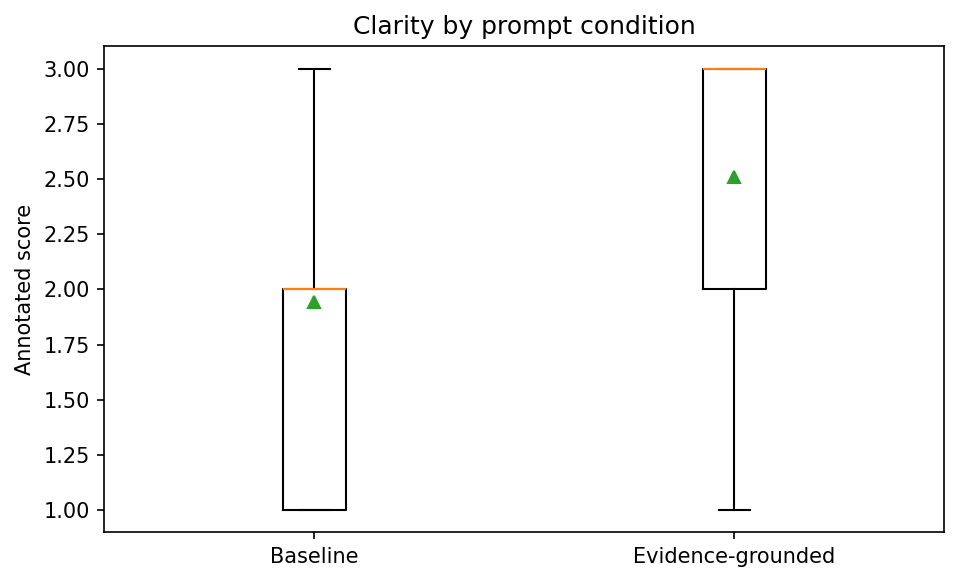

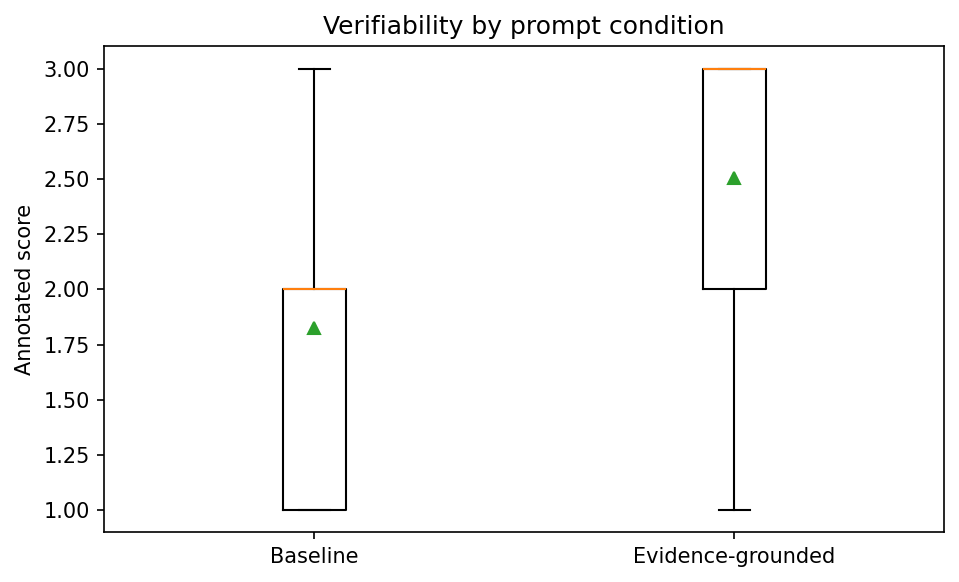

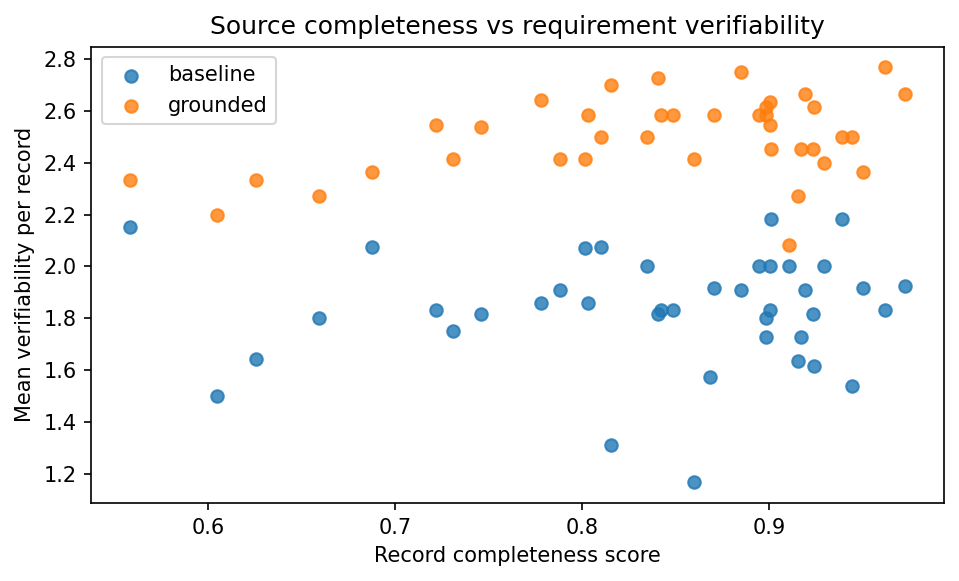

In [13]:
if ratings is not None:
    for metric in ["clarity", "verifiability"]:
        fig, ax = plt.subplots(figsize=(6.5, 4))
        groups = [rated.loc[rated.condition.eq(c), metric].dropna() for c in ["baseline", "grounded"]]
        ax.boxplot(groups, tick_labels=["Baseline", "Evidence-grounded"], showmeans=True)
        ax.set_title(f"{metric.title()} by prompt condition")
        ax.set_ylabel("Annotated score")
        fig.tight_layout()
        fig.savefig(OUT_DIR / f"{metric}_by_condition.png", dpi=300)
        plt.show()
    if "record_scores" in globals():
        fig, ax = plt.subplots(figsize=(6.5, 4))
        for condition, g in record_scores.groupby("condition"):
            ax.scatter(g["completeness"], g["mean_verifiability"], label=condition, alpha=.8)
        ax.set_xlabel("Record completeness score")
        ax.set_ylabel("Mean verifiability per record")
        ax.set_title("Source completeness vs requirement verifiability")
        ax.legend()
        fig.tight_layout()
        fig.savefig(OUT_DIR / "completeness_vs_verifiability.png", dpi=300)
        plt.show()
else:
    print("Figures skipped: rating-level data unavailable.")

## 12. Export, interpretation and publication checks

All generated tables/figures are saved under `outputs/`. Before manuscript use:
- Reconcile all counts from the same frozen CSVs and report a single flow diagram: records screened → records included → requirements generated per condition → requirements rated → double-rated subset.
- Report record-level denominators and missingness.
- Publish prompt text, model/version, generation date, decoding parameters, codebook, and analysis code.
- Use confidence intervals and effect sizes; adjust for multiple primary comparisons where appropriate.
- Account for clustering by source record in inferential modelling (e.g., mixed-effects ordinal/logistic models) before making journal-level claims.
- Report human semantic evidence-support judgements separately from exact-string quote matching.
- Do not label unsupported content “hallucination” unless the operational definition is explicit.
- Dummy values in the proposal are not experimental observations and must never be merged into this dataset.

### Current status
This notebook is a corrected, fail-fast analysis scaffold. A full rerun of the original experiment remains blocked until the raw CSVs, original scripts, prompt files, and annotation protocol are supplied. The output tables from the previous notebook have intentionally not been copied forward as if they had been reproduced.